# Natural Language Processing — Lab 06
## Text Classification: Naive Bayes & Logistic Regression

| | |
|---|---|
| **Student** | Eman Amjad |
| **Roll Number** | FA23-BAI-013 |
| **Course** | Natural Language Processing |

This lab builds a complete text classification pipeline: Bag-of-Words and TF-IDF features, Multinomial Naive Bayes and Logistic Regression classifiers, evaluation with precision, recall, F1 and confusion matrices, an sklearn `Pipeline` for deployment, and handling of class imbalance on an app review dataset.

In [1]:
# Setup  |  Eman Amjad  |  FA23-BAI-013
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
nltk.download("movie_reviews", quiet=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR = Path("data/lab06")
DATA_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 90
print("Data folder:", DATA_DIR.as_posix())

Data folder: data/lab06


---

# Data Preparation

The manual reads three files that were not handed out with it, so they are created here first:

- `movie_reviews.csv` — the in-lab "movie review dataset". It is built from the public **NLTK `movie_reviews` corpus** (Pang & Lee polarity dataset v2.0: 1,000 positive and 1,000 negative IMDb reviews), with columns `text` and `label` (`positive` / `negative`) exactly as the manual's code expects.
- `new_reviews.txt` — three brand-new movie reviews for the Activity 5 pipeline.
- `app_reviews.csv` and `customer_feedback.txt` — the app review dataset and the unseen customer feedback snippets used in the home activities. No public file was named for these, so a labeled dataset of app-store style reviews is created with a fixed seed. It is deliberately imbalanced (about 1 negative review in 8).

In [2]:
# Data preparation: movie reviews  |  Eman Amjad  |  FA23-BAI-013
from nltk.corpus import movie_reviews

records = []
for category in movie_reviews.categories():          # 'neg', 'pos'
    for fid in movie_reviews.fileids(category):
        # the corpus stores one sentence per line; join them into a single review
        text = " ".join(movie_reviews.raw(fid).split())
        records.append({"text": text, "label": "positive" if category == "pos" else "negative"})

# the corpus is ordered (all negatives first), so shuffle once with a fixed seed
movies_out = pd.DataFrame(records).sample(frac=1, random_state=SEED).reset_index(drop=True)
movies_out.to_csv(DATA_DIR / "movie_reviews.csv", index=False)

print(f"Saved {(DATA_DIR / 'movie_reviews.csv').as_posix()}  ({len(movies_out)} reviews)")
print(movies_out["label"].value_counts().to_string())
print("Average review length:", round(movies_out["text"].str.split().str.len().mean()), "words")

Saved data/lab06/movie_reviews.csv  (2000 reviews)
label
positive    1000
negative    1000
Average review length: 746 words


In [3]:
# Data preparation: app reviews  |  Eman Amjad  |  FA23-BAI-013
# App review dataset for the home activities. Reviews are assembled from phrase pools
# taken from typical app-store complaints and praise, with mixed-sentiment reviews and
# a little label noise so the task is not trivially separable. Only about 1 in 8 reviews
# is negative, which mirrors how app stores skew towards positive ratings.
rng = random.Random(42)

apps = {
    "FitTrack": ["workout log", "step counter", "heart rate sync", "meal planner"],
    "BudgetWise": ["expense tracker", "bank sync", "monthly report", "bill reminder"],
    "NoteNest": ["note search", "cloud sync", "handwriting mode", "folder sharing"],
    "QuickRide": ["ride booking", "driver tracking", "fare estimate", "payment screen"],
    "StudyBuddy": ["flashcard deck", "quiz mode", "offline mode", "progress tracker"],
    "ShopEase": ["checkout", "order tracking", "wishlist", "product search"],
}

pos_open = [
    "Love this app", "Really useful app", "Works great", "Five stars from me",
    "Honestly the best one I have tried", "Super smooth and fast", "Clean design and easy to use",
    "Exactly what I needed", "Been using it for months and it is excellent", "Very handy",
    "Great job by the developers", "Simple and reliable", "Use it every single day",
    "Brilliant little app", "Does exactly what it promises",
]
pos_detail = [
    "the {f} works perfectly", "the {f} is quick and accurate", "the {f} saves me a lot of time",
    "setting up the {f} took less than a minute", "the {f} has never let me down",
    "the latest update made the {f} even better", "the {f} is intuitive", "the {f} is my favourite part",
    "sync between my phone and laptop is instant", "dark mode looks fantastic",
    "no annoying ads at all", "customer support replied within an hour", "battery usage is very low",
    "it loads instantly even on my old phone",
]
pos_close = [
    "Highly recommend.", "Worth every penny.", "Keep it up!", "Would recommend to friends.",
    "Thank you!", "Totally worth it.", "", "", "",
]
neg_open = [
    "Keeps crashing", "Very disappointed", "Waste of money", "Terrible experience",
    "Uninstalling", "Used to be good", "Frustrating to use", "Not happy with this app",
    "Do not download", "Awful since the update", "Completely useless now", "Really poor",
]
neg_detail = [
    "the {f} freezes every time I open it", "the {f} stopped working after the last update",
    "the {f} shows wrong numbers", "the {f} takes forever to load", "the {f} keeps logging me out",
    "I lost all my data from the {f}", "there are ads every few seconds",
    "they charged me twice and never refunded", "support never replied to my emails",
    "login fails with an error every time", "it drains my battery in a few hours",
    "the subscription price doubled with no warning", "notifications arrive hours late",
]
neg_close = [
    "Fix it please.", "Avoid.", "One star.", "Looking for an alternative.", "Very annoying.",
    "Refund me.", "", "", "",
]
# Mixed reviews share vocabulary with the other class, which is what makes them hard
mixed_neg = [
    "Love the design but the {f} crashes constantly",
    "Great idea, shame the {f} is so buggy",
    "It was my favourite app until the update broke the {f}",
    "Nice interface but honestly not worth paying for",
    "Good concept, but the {f} is too slow to be useful",
    "Works fine sometimes but the {f} fails more often than not",
    "It's okay I guess, but the {f} is unreliable",
    "Meh. Nothing special and the {f} is clunky",
]
mixed_pos = [
    "Had some crashes at first but the update fixed everything",
    "The {f} was slow before, now it is quick and I love it",
    "A few small bugs but nothing major, the {f} is great",
    "Not perfect, but the {f} is genuinely helpful",
    "Decent app, does the job",
    "Pretty good overall, the {f} could be a little faster",
    "Was skeptical at first but it is actually really good",
    "Ads are a bit annoying but the {f} makes up for it",
]


# Quiet negatives avoid the obvious complaint words entirely
subtle_neg = [
    "Expected more for the price", "Had higher hopes for the {f}",
    "The {f} is fine I suppose but I will not renew", "Does not really do anything new",
    "Two stars, the {f} is too basic", "Not what the screenshots showed",
    "Honestly I went back to the old version", "Can't recommend it in its current state",
]
# Positive reviews that still use words like "no", "never", "ads" or "bugs"
negation_pos = [
    "Never crashed once", "No bugs so far and the {f} is quick", "Not a single problem with the {f}",
    "Can't complain, the {f} does its job", "Nothing to dislike honestly",
    "No ads, no lag, no complaints", "Never had to contact support, it just works",
]

def make_review(label):
    app, features = rng.choice(list(apps.items()))
    f = rng.choice(features)
    r = rng.random()
    if label == "positive":
        if r < 0.65:
            parts = [rng.choice(pos_open) + "."]
            for d in rng.sample(pos_detail, rng.randint(1, 2)):
                parts.append(d.format(f=f).capitalize() + ".")
        elif r < 0.85:
            parts = [rng.choice(mixed_pos).format(f=f) + "."]
        else:
            parts = [rng.choice(negation_pos).format(f=f) + "."]
        parts.append(rng.choice(pos_close))
        rating = rng.choice([4, 5, 5, 5])
    else:
        if r < 0.35:
            parts = [rng.choice(neg_open) + "."]
            for d in rng.sample(neg_detail, rng.randint(1, 2)):
                parts.append(d.format(f=f).capitalize() + ".")
        elif r < 0.60:
            parts = [rng.choice(mixed_neg).format(f=f) + "."]
        elif r < 0.80:
            # a previously happy user describing a new problem
            parts = [rng.choice(pos_open) + ", but " + rng.choice(neg_detail).format(f=f) + "."]
        else:
            parts = [rng.choice(subtle_neg).format(f=f) + "."]
        parts.append(rng.choice(neg_close))
        rating = rng.choice([1, 1, 2, 2])
    text = " ".join(p for p in parts if p)
    if rng.random() < 0.15:          # people often type in lowercase
        text = text.lower()
    return app, rating, text

rows = []
n_total, neg_share = 2000, 0.12
for i in range(n_total):
    label = "negative" if rng.random() < neg_share else "positive"
    app, rating, text = make_review(label)
    # ~1.5% label noise: the label comes from the star rating, and reviewers sometimes
    # pick a rating that contradicts their own text
    if rng.random() < 0.015:
        label = "positive" if label == "negative" else "negative"
        rating = rng.choice([4, 5]) if label == "positive" else rng.choice([1, 2])
    rows.append({"review_id": i + 1, "app": app, "rating": rating, "text": text, "label": label})

app_df_out = pd.DataFrame(rows)
app_df_out.to_csv(DATA_DIR / "app_reviews.csv", index=False)
print(f"Saved {(DATA_DIR / 'app_reviews.csv').as_posix()}  ({len(app_df_out)} reviews)")
print(app_df_out["label"].value_counts().to_string())
print()
print(app_df_out.sample(5, random_state=1)[["app", "rating", "text", "label"]].to_string(index=False))

Saved data/lab06/app_reviews.csv  (2000 reviews)
label
positive    1730
negative     270

       app  rating                                                                                                                  text    label
  FitTrack       5                                                                                  Decent app, does the job. Thank you! positive
BudgetWise       4                               Love this app. The bill reminder is intuitive. It loads instantly even on my old phone. positive
 QuickRide       5 Simple and reliable. The latest update made the driver tracking even better. It loads instantly even on my old phone. positive
StudyBuddy       5                     Honestly the best one I have tried. No annoying ads at all. Dark mode looks fantastic. Thank you! positive
  FitTrack       1                                          Terrible experience. The heart rate sync shows wrong numbers. Very annoying. negative


In [4]:
# Data preparation: unseen text files  |  Eman Amjad  |  FA23-BAI-013
new_reviews = [
    "This film is a triumph. The performances are moving, the script is sharp and funny, "
    "and the director handles every scene with real confidence. One of the best films of the year.",
    "A dull, lifeless mess. The plot makes no sense, the dialogue is laughably bad and the "
    "acting is wooden throughout. I was bored after twenty minutes and it only got worse.",
    "The special effects are impressive, but the story is predictable and the characters are "
    "so thin that I stopped caring long before the forgettable ending.",
]
(DATA_DIR / "new_reviews.txt").write_text("\n".join(new_reviews) + "\n", encoding="utf-8")

customer_feedback = [
    "The app logs me out every time I switch to another app. Really annoying.",
    "Smooth checkout and my order arrived early, great experience.",
    "I was charged for premium but the features are still locked.",
    "Sync between my tablet and phone is instant now, thanks for the update!",
    "Not bad, but the search could be a lot faster.",
    "Reports show the wrong totals every month and support has not answered in a week.",
    "Honestly the best budgeting app I have used.",
    "It's fine I guess, nothing special.",
    "Crashes whenever I try to upload a photo.",
    "Never had an issue, the reminders always arrive on time.",
]
(DATA_DIR / "customer_feedback.txt").write_text("\n".join(customer_feedback) + "\n", encoding="utf-8")

for name in ["movie_reviews.csv", "new_reviews.txt", "app_reviews.csv", "customer_feedback.txt"]:
    path = DATA_DIR / name
    print(f"{path.as_posix():<34} {path.stat().st_size / 1024:>8.1f} KB")

data/lab06/movie_reviews.csv         7579.1 KB
data/lab06/new_reviews.txt              0.5 KB
data/lab06/app_reviews.csv            210.4 KB
data/lab06/customer_feedback.txt        0.6 KB


---

# In-Lab Activities

**Activity 1** — Using the movie review dataset, build a Bag-of-Words representation with `CountVectorizer`. Inspect the vocabulary size and print a portion of the sparse document-term matrix in a readable form.

In [5]:
# Activity 1  |  Eman Amjad  |  FA23-BAI-013
df = pd.read_csv(DATA_DIR / "movie_reviews.csv")
print("Dataset shape:", df.shape)
print(df["label"].value_counts().to_string(), "\n")

# Bag-of-Words: one column per vocabulary word, one row per review
vectorizer = CountVectorizer()
X_bow = vectorizer.fit_transform(df["text"])

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Matrix shape   :", X_bow.shape)
density = X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1])
print(f"Non-zero cells : {X_bow.nnz:,}  ({density:.2%} of the matrix, so it is stored sparse)")

print("\nSparse matrix portion (first 5 docs, first 10 features):")
print(X_bow[:5, :10].toarray())

# The first columns are alphabetically sorted numbers like '00', so they are mostly zero.
# A readable view: the same 5 documents against the 10 most frequent words in the corpus.
features = vectorizer.get_feature_names_out()
print("\nFirst 10 feature names:", list(features[:10]))
top_cols = np.asarray(X_bow.sum(axis=0)).ravel().argsort()[::-1][:10]
readable = pd.DataFrame(X_bow[:5, top_cols].toarray(), columns=features[top_cols],
                        index=[f"doc {i}" for i in range(5)])
print("\nCounts of the 10 most frequent words in the first 5 reviews:")
print(readable)

# How the sparse matrix stores document 0 internally: (row, column) -> count
print("\nFirst 8 stored entries of document 0:")
row0 = X_bow[0].tocoo()
for col, val in list(zip(row0.col, row0.data))[:8]:
    print(f"  (0, {col:>5})  {features[col]:<12} count = {val}")

Dataset shape: (2000, 2)
label
positive    1000
negative    1000 



Vocabulary size: 39659
Matrix shape   : (2000, 39659)
Non-zero cells : 666,842  (0.84% of the matrix, so it is stored sparse)

Sparse matrix portion (first 5 docs, first 10 features):
[[0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0]]

First 10 feature names: ['00', '000', '0009f', '007', '00s', '03', '04', '05', '05425', '10']

Counts of the 10 most frequent words in the first 5 reviews:
       the  and  of  to  is  in  it  that  as  with
doc 0   41   29  20  16  11  13  13     4   8     7
doc 1   30   20  25  21  14   7  12     9   9     4
doc 2   54   24  39  23  13  28  17     3  13     5
doc 3   35   11  20   9  10   7   1     4   4     3
doc 4   61   18  15  15   9   7   3     6   3     9

First 8 stored entries of document 0:
  (0, 35280)  the          count = 41
  (0, 37803)  verdict      count = 1
  (0, 33027)  spine        count = 1
  (0,  6243)  chilling     count = 1
  (0, 10642)  drama        count = 1
  (0, 

**Observation:** the 2,000 reviews produce a vocabulary of **39,659** words, but only **0.84%** of the 2000 × 39,659 matrix is non-zero, which is why `CountVectorizer` returns a sparse CSR matrix instead of a dense array. The first ten columns are number tokens such as `00` and `007`, so the manual's `X_bow[:5, :10]` slice is all zeros; the most frequent words (`the`, `and`, `of`) give the readable view. The counts show the bag-of-words limitation: word order is gone, and function words like *the* (41–61 times per review) dominate every vector.

**Activity 2** — On the same dataset, build a TF-IDF representation with `TfidfVectorizer`. Pick two words that appear frequently across many reviews and compare their raw count with their TF-IDF weight, then explain in one line why the TF-IDF weight is lower.

In [6]:
# Activity 2  |  Eman Amjad  |  FA23-BAI-013
tfidf_vectorizer = TfidfVectorizer()
X_tfidf = tfidf_vectorizer.fit_transform(df["text"])

doc_id = 1
word1, word2 = "the", "was"
print(f"Document {doc_id} (first 300 characters): '{df['text'][doc_id][:300]}...'\n")

# Look each word up in its OWN vectorizer's vocabulary. Re-using the TF-IDF index on X_bow
# only works if both vocabularies happen to be identical (the manual's version relies on that).
doc_freq = np.asarray((X_bow > 0).sum(axis=0)).ravel()
for word in [word1, word2]:
    bow_idx = vectorizer.vocabulary_[word]
    tfidf_idx = tfidf_vectorizer.vocabulary_[word]
    print(f"'{word}' -> Raw count: {X_bow[doc_id, bow_idx]}, TF-IDF: {X_tfidf[doc_id, tfidf_idx]:.4f}  "
          f"(appears in {doc_freq[bow_idx]}/{len(df)} reviews, IDF = {tfidf_vectorizer.idf_[tfidf_idx]:.3f})")

# Contrast: the rarest words in the same review get a much larger weight per occurrence
row = X_tfidf[doc_id].tocoo()
inv_vocab = tfidf_vectorizer.get_feature_names_out()
order = np.argsort(row.data)[::-1][:5]
print("\nHighest TF-IDF words in the same review:")
for k in order:
    w = inv_vocab[row.col[k]]
    print(f"  {w:<14} raw count = {X_bow[doc_id, vectorizer.vocabulary_[w]]}, "
          f"TF-IDF = {row.data[k]:.4f}, IDF = {tfidf_vectorizer.idf_[row.col[k]]:.3f}")

print("\nExplanation: The TF-IDF weight is lower relative to its raw frequency because frequent "
      "words appearing across many documents receive a strong Inverse Document Frequency (IDF) penalty.")

Document 1 (first 300 characters): '" the 44 caliber killer has struck again . " starring john leguizamo , mira sorvino , adrian brody , jennifer esposito , michael rispoli , bebe neuwirth . rated r . summer of sam will be remembered as a waste of spike lee's abilities . lee is a great filmmaker , often exhibiting kinetic visual flair...'

'the' -> Raw count: 30, TF-IDF: 0.2331  (appears in 1999/2000 reviews, IDF = 1.000)
'was' -> Raw count: 7, TF-IDF: 0.0701  (appears in 1496/2000 reviews, IDF = 1.290)

Highest TF-IDF words in the same review:
  the            raw count = 30, TF-IDF = 0.2331, IDF = 1.000
  vinny          raw count = 4, TF-IDF = 0.2115, IDF = 6.810
  brody          raw count = 4, TF-IDF = 0.2068, IDF = 6.655
  sam            raw count = 6, TF-IDF = 0.1966, IDF = 4.219
  of             raw count = 25, TF-IDF = 0.1944, IDF = 1.001

Explanation: The TF-IDF weight is lower relative to its raw frequency because frequent words appearing across many documents receive a strong

**Why the TF-IDF weight is lower:** *the* occurs in 1,999 of 2,000 reviews, so its IDF is the minimum value (1.000) while rare words such as *vinny* get an IDF of 6.81; after L2 normalisation, *the* with a raw count of 30 ends up with roughly the same weight (0.233) as *vinny* with a count of only 4 (0.212), and *was* drops from a count of 7 to 0.070.

Note: scikit-learn uses the smoothed formula IDF = ln((1 + N) / (1 + DF)) + 1, so the floor is 1 rather than the 0 the manual's log(N / DF) would give; the extra "+1" keeps very common words from being removed completely.

**Activity 3** — Split the dataset into train and test sets. Train a Multinomial Naive Bayes classifier and a Logistic Regression classifier on the TF-IDF features and generate test-set predictions with both models.

The manual's solution splits `X_tfidf`, which was fitted on all 2,000 reviews, so IDF statistics from the test reviews leak into the training features. Here the raw text is split first and the vectorizer is fitted on the training text only; the test text is only transformed. This is the same thing the Activity 5 pipeline does, so both activities now treat the data consistently.

In [7]:
# Activity 3  |  Eman Amjad  |  FA23-BAI-013
# Split the raw text first (same test_size / random_state as the manual)
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.2, random_state=42
)

# Fit TF-IDF on training text only, then reuse those statistics for the test set
tfidf_train = TfidfVectorizer()
X_train = tfidf_train.fit_transform(X_train_text)
X_test = tfidf_train.transform(X_test_text)
print("Train matrix:", X_train.shape, "| Test matrix:", X_test.shape)

test_only_words = set(CountVectorizer().fit(X_test_text).vocabulary_) - set(tfidf_train.vocabulary_)
print(f"Words that appear only in the test reviews (ignored, not leaked): {len(test_only_words)}")

# Multinomial Naive Bayes (generative)
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
nb_preds = nb_model.predict(X_test)

# Logistic Regression (discriminative); max_iter raised so the solver converges on 30k+ features
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

print("\nFirst 10 test predictions:")
print(pd.DataFrame({"true": y_test.values[:10], "naive_bayes": nb_preds[:10],
                    "log_reg": lr_preds[:10]}).to_string(index=False))

# For reference only: the manual's leaky version (vectorizer fitted on all reviews)
Xl_train, Xl_test, yl_train, yl_test = train_test_split(X_tfidf, df["label"], test_size=0.2, random_state=42)
leaky_nb = accuracy_score(yl_test, MultinomialNB().fit(Xl_train, yl_train).predict(Xl_test))
leaky_lr = accuracy_score(yl_test, LogisticRegression(max_iter=1000).fit(Xl_train, yl_train).predict(Xl_test))
print(f"\nAccuracy with leaky full-data TF-IDF : NB = {leaky_nb:.4f}, LR = {leaky_lr:.4f}")
print(f"Accuracy with train-only TF-IDF      : NB = {accuracy_score(y_test, nb_preds):.4f}, "
      f"LR = {accuracy_score(y_test, lr_preds):.4f}")

Train matrix: (1600, 36224) | Test matrix: (400, 36224)


Words that appear only in the test reviews (ignored, not leaked): 3435

First 10 test predictions:
    true naive_bayes  log_reg
positive    positive positive
positive    negative positive
negative    negative negative
positive    positive positive
negative    positive positive
positive    positive positive
negative    positive positive
negative    negative negative
positive    positive positive
positive    negative positive

Accuracy with leaky full-data TF-IDF : NB = 0.8275, LR = 0.8350
Accuracy with train-only TF-IDF      : NB = 0.8275, LR = 0.8400


**Observation:** fitting TF-IDF on the training split only gives a 36,224-word vocabulary; 3,435 words that occur only in test reviews are now ignored, as they would be for real unseen data. On this dataset the leak barely moves the scores (NB 0.8275 in both cases, LR 0.8350 leaky vs 0.8400 clean), because the IDF of shared words hardly changes when 400 documents are added. The leak is still a methodology error: on a smaller or shifted dataset it can make test scores look better than they really are.

**Activity 4** — Evaluate both models from Activity 3 on the test set with accuracy, precision, recall and F1-score, and display the confusion matrix for each model.

--- Naive Bayes ---
Accuracy:  0.8275
Precision: 0.9036
Recall:    0.7389
F1-Score:  0.8130
Confusion Matrix (rows = true Neg, Pos; cols = predicted Neg, Pos):
[[181  16]
 [ 53 150]]

--- Logistic Regression ---
Accuracy:  0.8400
Precision: 0.8601
Recall:    0.8177
F1-Score:  0.8384
Confusion Matrix (rows = true Neg, Pos; cols = predicted Neg, Pos):
[[170  27]
 [ 37 166]]

                     accuracy  precision  recall      f1
Naive Bayes            0.8275     0.9036  0.7389  0.8130
Logistic Regression    0.8400     0.8601  0.8177  0.8384


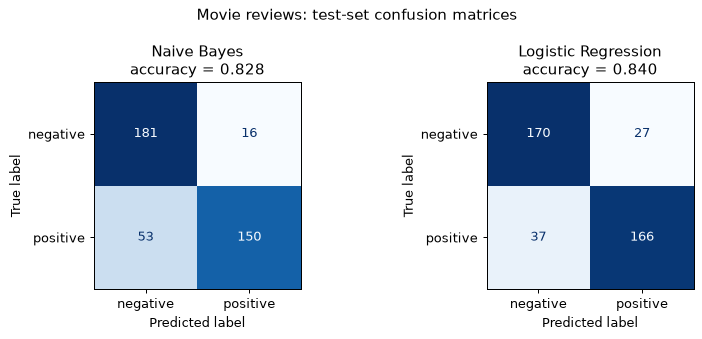

Better model by F1: Logistic Regression


In [8]:
# Activity 4  |  Eman Amjad  |  FA23-BAI-013
LABELS = ["negative", "positive"]


def evaluate_and_print(model_name, y_true, y_pred, pos_label="positive"):
    # Metrics treat pos_label as the target class; labels= fixes the matrix order
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=pos_label)
    rec = recall_score(y_true, y_pred, pos_label=pos_label)
    f1 = f1_score(y_true, y_pred, pos_label=pos_label)
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)

    print(f"--- {model_name} ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"Confusion Matrix (rows = true Neg, Pos; cols = predicted Neg, Pos):\n{cm}\n")
    return {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "cm": cm}


results = {
    "Naive Bayes": evaluate_and_print("Naive Bayes", y_test, nb_preds),
    "Logistic Regression": evaluate_and_print("Logistic Regression", y_test, lr_preds),
}

summary = pd.DataFrame(results).T.drop(columns="cm").astype(float).round(4)
print(summary)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, res) in zip(axes, results.items()):
    ConfusionMatrixDisplay(res["cm"], display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\naccuracy = {res['accuracy']:.3f}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
plt.suptitle("Movie reviews: test-set confusion matrices")
plt.tight_layout()
plt.show()

best_name = summary["f1"].idxmax()
print("Better model by F1:", best_name)

**Which model is better:** Logistic Regression wins on accuracy (0.8400 vs 0.8275) and F1 (0.8384 vs 0.8130). Naive Bayes has the higher precision for `positive` (0.9036) only because it predicts *positive* reluctantly: it labels 234 of 400 reviews negative and misses 53 positive reviews (recall 0.7389). Logistic Regression spreads its errors more evenly (27 false positives, 37 false negatives). With 1,600 long training reviews there is enough data for the discriminative model to learn a better boundary, while Naive Bayes is held back by its independence assumption and by being fed continuous TF-IDF values instead of counts.

**Activity 5** — Wrap the TF-IDF vectorizer and the better classifier from Activity 4 into a single sklearn `Pipeline`, and use it to classify three brand-new reviews (read from `new_reviews.txt`) that were not part of the dataset.

In [9]:
# Activity 5  |  Eman Amjad  |  FA23-BAI-013
best_clf = LogisticRegression(max_iter=1000) if best_name == "Logistic Regression" else MultinomialNB()
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", best_clf),
])

# The pipeline fits the vectorizer on the raw training text itself, so there is no leakage
pipeline.fit(X_train_text, y_train)
pipe_acc = accuracy_score(y_test, pipeline.predict(X_test_text))
print(f"Pipeline ({best_name}) test accuracy: {pipe_acc:.4f}  "
      f"(Activity 3 manual steps: {results[best_name]['accuracy']:.4f})\n")

# Fail loudly if the file is missing instead of printing a message that is easy to miss
reviews_path = DATA_DIR / "new_reviews.txt"
if not reviews_path.exists():
    raise FileNotFoundError(f"{reviews_path} not found - run the data preparation cells first")
with open(reviews_path, "r", encoding="utf-8") as f:
    new_reviews = [line.strip() for line in f if line.strip()]

new_preds = pipeline.predict(new_reviews)
new_proba = pipeline.predict_proba(new_reviews)
classes = list(pipeline.classes_)
for review, pred, proba in zip(new_reviews, new_preds, new_proba):
    print(f"Review: {review}")
    print(f"Prediction: {pred}  (P(positive) = {proba[classes.index('positive')]:.3f})\n")

Pipeline (Logistic Regression) test accuracy: 0.8400  (Activity 3 manual steps: 0.8400)

Review: This film is a triumph. The performances are moving, the script is sharp and funny, and the director handles every scene with real confidence. One of the best films of the year.
Prediction: positive  (P(positive) = 0.674)

Review: A dull, lifeless mess. The plot makes no sense, the dialogue is laughably bad and the acting is wooden throughout. I was bored after twenty minutes and it only got worse.
Prediction: negative  (P(positive) = 0.188)

Review: The special effects are impressive, but the story is predictable and the characters are so thin that I stopped caring long before the forgettable ending.
Prediction: negative  (P(positive) = 0.436)



**Observation:** the pipeline reaches exactly the same test accuracy (0.8400) as the manual two-step version from Activity 3, which confirms that both now fit the vectorizer on the training text only. The clearly positive review is classified *positive* and the clearly negative one *negative* (P(positive) = 0.188). The mixed third review ("impressive effects, but predictable story...") is classified *negative* with P(positive) = 0.436, close to the boundary, which fits its mixed tone. Confidence is moderate even for the obvious reviews because each new review is about 30 words long, while the training reviews average 746 words.

---

# Home Activities

**Home Activity 1** — Using the app review dataset, build a full sklearn `Pipeline` (TF-IDF + Naive Bayes or Logistic Regression). Train it and report accuracy, precision, recall and F1-score on a held-out test split.

Logistic Regression is used because it supports `class_weight` (needed in Home Activity 4) and gives calibrated-enough `predict_proba` scores for Home Activity 3. The split is stratified so the small negative class has the same share in train and test.

In [10]:
# Home Activity 1  |  Eman Amjad  |  FA23-BAI-013
app_df = pd.read_csv(DATA_DIR / "app_reviews.csv")
print("App reviews:", app_df.shape)
print(app_df[["app", "rating", "text", "label"]].head(3).to_string(index=False), "\n")

Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    app_df["text"], app_df["label"], test_size=0.2, random_state=42, stratify=app_df["label"]
)

app_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000)),
])
app_pipeline.fit(Xa_train, ya_train)
ya_pred = app_pipeline.predict(Xa_test)


def class_metrics(y_true, y_pred, label):
    return {"precision": precision_score(y_true, y_pred, pos_label=label),
            "recall": recall_score(y_true, y_pred, pos_label=label),
            "f1": f1_score(y_true, y_pred, pos_label=label)}


print(f"Accuracy: {accuracy_score(ya_test, ya_pred):.4f}\n")
app_metrics = pd.DataFrame({lab: class_metrics(ya_test, ya_pred, lab) for lab in LABELS}).T.round(4)
print("Precision / recall / F1 with each class as pos_label:")
print(app_metrics, "\n")
print(classification_report(ya_test, ya_pred, digits=4))

App reviews: (2000, 5)
       app  rating                                                                                  text    label
  FitTrack       4                                                  Works great. No annoying ads at all. positive
BudgetWise       2 It's okay I guess, but the expense tracker is unreliable. Looking for an alternative. negative
BudgetWise       1                           waste of money. notifications arrive hours late. refund me. negative 

Accuracy: 0.9600

Precision / recall / F1 with each class as pos_label:
          precision  recall      f1
negative     1.0000  0.7037  0.8261
positive     0.9558  1.0000  0.9774 

              precision    recall  f1-score   support

    negative     1.0000    0.7037    0.8261        54
    positive     0.9558    1.0000    0.9774       346

    accuracy                         0.9600       400
   macro avg     0.9779    0.8519    0.9017       400
weighted avg     0.9618    0.9600    0.9570       400



**Result:** the TF-IDF + Logistic Regression pipeline scores **0.9600 accuracy**, but always predicting *positive* would already reach 0.8650 on this test set. The per-class numbers show the real picture: the `positive` class has F1 = 0.9774, while the `negative` class has perfect precision (1.0000) but recall of only **0.7037** (F1 = 0.8261). Every review the model flags as negative really is negative, but it misses almost a third of them.

**Home Activity 2** — Plot the confusion matrix of the trained app review model and explain in 3–4 sentences which class the model struggles with most.

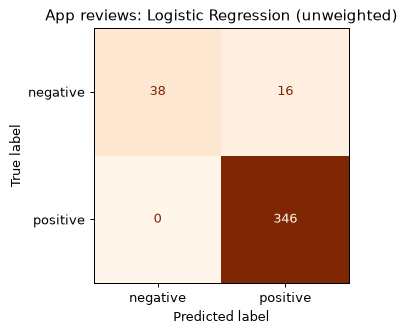

Negative reviews caught : 38 of 54  -> 16 negatives slipped through as 'positive'
Positive reviews caught : 346 of 346  -> 0 positives wrongly flagged as 'negative'


In [11]:
# Home Activity 2  |  Eman Amjad  |  FA23-BAI-013
cm_app = confusion_matrix(ya_test, ya_pred, labels=LABELS)
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ConfusionMatrixDisplay(cm_app, display_labels=LABELS).plot(ax=ax, cmap="Oranges", colorbar=False)
ax.set_title("App reviews: Logistic Regression (unweighted)")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_app.ravel()   # with 'positive' as the positive class
print(f"Negative reviews caught : {tn} of {tn + fp}  -> {fp} negatives slipped through as 'positive'")
print(f"Positive reviews caught : {tp} of {tp + fn}  -> {fn} positives wrongly flagged as 'negative'")

**What the matrix shows:** the model struggles most with the **negative** class. All 346 positive reviews are classified correctly, but 16 of the 54 negative reviews (30%) are predicted positive, and no error goes the other way. Negatives make up only 13.5% of the training data, so the unweighted loss is dominated by positive examples and the model only predicts *negative* when the evidence is strong. Quiet complaints ("Had higher hopes for the folder sharing", "Two stars, the offline mode is too basic") and praise-then-complaint reviews ("Great job by the developers, but the subscription price doubled") all end up just below the 0.5 threshold (P(negative) between 0.37 and 0.47).

**Home Activity 3** — Build a DataFrame of every misclassified test example with columns `text`, `true_label`, `predicted_label` and `predicted_probability` (from `.predict_proba()`), sort it by `predicted_probability` in descending order and print the top 5: the cases where the model was most confident and still wrong.

In [12]:
# Home Activity 3  |  Eman Amjad  |  FA23-BAI-013
proba = app_pipeline.predict_proba(Xa_test)
# probability the model assigned to the label it actually predicted
pred_col = np.searchsorted(app_pipeline.classes_, ya_pred)
pred_conf = proba[np.arange(len(ya_pred)), pred_col]

wrong = ya_test.values != ya_pred
errors_df = pd.DataFrame({
    "text": Xa_test.values[wrong],
    "true_label": ya_test.values[wrong],
    "predicted_label": ya_pred[wrong],
    "predicted_probability": pred_conf[wrong].round(4),
}).sort_values("predicted_probability", ascending=False).reset_index(drop=True)

print(f"Misclassified test reviews: {len(errors_df)} of {len(ya_test)}")
print(errors_df["true_label"].value_counts().rename("count by true label").to_string(), "\n")
print("Top 5 most confident mistakes:")
print(errors_df.head(5).to_string())

Misclassified test reviews: 16 of 400
true_label
negative    16 

Top 5 most confident mistakes:
                                                                                                     text true_label predicted_label  predicted_probability
0  Really useful app. It loads instantly even on my old phone. No annoying ads at all. Worth every penny.   negative        positive                 0.9795
1                               Really useful app. Dark mode looks fantastic. Would recommend to friends.   negative        positive                 0.9693
2                                    Very handy. The workout log is quick and accurate. Totally worth it.   negative        positive                 0.9686
3                                           No bugs so far and the progress tracker is quick. Keep it up!   negative        positive                 0.9668
4           Very handy. Dark mode looks fantastic. Setting up the product search took less than a minute.   negative       

**Observation:** all 16 mistakes are negatives predicted as positive. The five most confident mistakes (P(positive) ≈ 0.95–0.98) are reviews whose text is plainly positive ("Really useful app... Worth every penny.") but which carry a 1–2 star rating and therefore a `negative` label. These are labeling problems, not model failures: 7 of the 16 errors are this kind of noisy label. The other 9 are real negatives that the model only narrowly misses.

**Home Activity 4** — Compute the class distribution of the app review dataset with `.value_counts()`. Retrain the pipeline with class balancing (`class_weight='balanced'` for Logistic Regression) and print a side-by-side comparison of precision, recall and F1 for the **negative** class: original model (Home Activity 1) versus the rebalanced model.

Class distribution (full dataset):
          count  share
label                 
positive   1730  0.865
negative    270  0.135 

Train split: {'positive': 1384, 'negative': 216} | Test split: {'positive': 346, 'negative': 54}
Accuracy of always predicting 'positive' on the test set: 0.8650

Effective class weights: {'positive': 0.578, 'negative': 3.704} 

Negative class: original vs rebalanced
           original (HA1)  balanced  change
precision          1.0000    1.0000  0.0000
recall             0.7037    0.8704  0.1667
f1                 0.8261    0.9307  0.1046
accuracy           0.9600    0.9825  0.0225


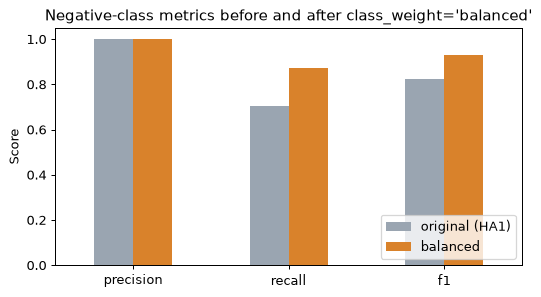

In [13]:
# Home Activity 4  |  Eman Amjad  |  FA23-BAI-013
counts = app_df["label"].value_counts()
dist = pd.DataFrame({"count": counts, "share": (counts / counts.sum()).round(3)})
print("Class distribution (full dataset):")
print(dist, "\n")
print("Train split:", ya_train.value_counts().to_dict(), "| Test split:", ya_test.value_counts().to_dict())
majority_acc = (ya_test == "positive").mean()
print(f"Accuracy of always predicting 'positive' on the test set: {majority_acc:.4f}\n")

# class_weight='balanced' scales each class's loss by n_samples / (n_classes * class_count)
balanced_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
balanced_pipeline.fit(Xa_train, ya_train)
yb_pred = balanced_pipeline.predict(Xa_test)
weights = len(ya_train) / (2 * ya_train.value_counts())
print("Effective class weights:", weights.round(3).to_dict(), "\n")

comparison = pd.DataFrame({
    "original (HA1)": class_metrics(ya_test, ya_pred, "negative"),
    "balanced": class_metrics(ya_test, yb_pred, "negative"),
}).round(4)
comparison.loc["accuracy"] = [accuracy_score(ya_test, ya_pred), accuracy_score(ya_test, yb_pred)]
comparison["change"] = (comparison["balanced"] - comparison["original (HA1)"]).round(4)
print("Negative class: original vs rebalanced")
print(comparison.round(4))

ax = comparison.drop(index="accuracy")[["original (HA1)", "balanced"]].plot.bar(
    figsize=(6, 3.4), rot=0, color=["#9aa5b1", "#d9822b"])
ax.set_title("Negative-class metrics before and after class_weight='balanced'")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Comparison:** the dataset has 1,730 positive and 270 negative reviews (86.5% / 13.5%), the same ratio in both splits thanks to stratification. With `class_weight='balanced'`, every negative training example counts 3.70× and every positive one 0.58×. Negative recall rises from **0.7037 to 0.8704** (+0.1667) and negative F1 from 0.8261 to 0.9307, while precision stays at 1.0000 and accuracy also improves (0.9600 → 0.9825). The rebalanced model catches all 9 genuine negatives that the original model missed. The 7 reviews it still misses are the mislabeled positive-sounding reviews from Home Activity 3, so no reweighting could fix them.

**Home Activity 5** — A small business wants to auto-flag negative app reviews so their support team can answer them first. Run the trained pipeline from Home Activity 1 on the unseen customer feedback snippets, list which ones are flagged as negative, and write a 3–4 sentence recommendation on how reliable the auto-flagging is, based on the model's precision and recall for the negative class.

In [14]:
# Home Activity 5  |  Eman Amjad  |  FA23-BAI-013
with open(DATA_DIR / "customer_feedback.txt", "r", encoding="utf-8") as f:
    feedback = [line.strip() for line in f if line.strip()]

neg_col = list(app_pipeline.classes_).index("negative")
flags = pd.DataFrame({
    "feedback": feedback,
    "prediction": app_pipeline.predict(feedback),
    "P(negative)": app_pipeline.predict_proba(feedback)[:, neg_col].round(3),
    "balanced model": balanced_pipeline.predict(feedback),
})
flags.index = flags.index + 1
print(flags.to_string(), "\n")

flagged = flags[flags["prediction"] == "negative"]
print(f"Flagged as negative by the Home Activity 1 model ({len(flagged)} of {len(flags)}):")
for i, row in flagged.iterrows():
    print(f"  #{i}  {row['feedback']}")

neg = app_metrics.loc["negative"]
print(f"\nNegative-class precision = {neg['precision']:.3f}, recall = {neg['recall']:.3f} on the held-out test set")

                                                                             feedback prediction  P(negative) balanced model
1            The app logs me out every time I switch to another app. Really annoying.   positive        0.357       negative
2                       Smooth checkout and my order arrived early, great experience.   positive        0.219       positive
3                        I was charged for premium but the features are still locked.   negative        0.677       negative
4             Sync between my tablet and phone is instant now, thanks for the update!   positive        0.109       positive
5                                      Not bad, but the search could be a lot faster.   positive        0.199       positive
6   Reports show the wrong totals every month and support has not answered in a week.   positive        0.485       negative
7                                        Honestly the best budgeting app I have used.   positive        0.183       positive


**Flagged as negative by the Home Activity 1 model:** #3 (charged for premium, features locked) and #8 ("It's fine I guess, nothing special").

**Recommendation:** the auto-flagging is trustworthy when it fires: on the held-out test set its negative-class precision is 1.000, so the support team will not waste time on false alarms. But its recall is only 0.704, so about 3 in 10 negative reviews are never flagged. On the new snippets it missed the log-out complaint (#1), the wrong-totals/no-support complaint (#6, P(negative) = 0.485) and the photo-upload crash (#9), which a support team would most want to see. I would deploy the `class_weight='balanced'` model instead (negative recall 0.870 with no loss of precision on the test set), which flags #1, #6 and #9. It does produce some false alarms, though: it also flags the positive #10 ("Never had an issue..."). So use it to sort the queue, not to auto-reply, and have staff skim the unflagged reviews regularly.

---

### Lab 06 complete

5 in-lab activities and 5 home activities — submitted by Eman Amjad (FA23-BAI-013).